# Project 5: Learning candle-data repair instructions with PEFT-LoRA

**Name:** To be completed  
**Course:** CSCI 4820 - section to be completed  
**Project:** 5

The task is to predict whether a corrupted candle window can be recovered and,
if so, the ordered registered repair functions. The model returns exactly
`{"recoverable": true, "operations": [...]}` or
`{"recoverable": false, "operations": []}`. A negative decision omits the whole
window in the final cleaning demonstration. Negative examples remain in training.

`candleprep` is a separate, CPU-only dataset generator and oracle. It receives
the original data and corruption history offline, verifies repairs, and saves
targets. Model prompts contain only corrupted CSV and fixed task instructions.
Routine metrics compare instructions without executing repairs.

**Status:** CPU data generation and scoring can run now. Full before/after model
performance is not yet measured. Saved brief GPU evidence appears below when
available. Enable any further GPU stages explicitly.
Final results must also be tested on TAMU Launch's 24 GB A30.


## 1. Configuration

Use the global Python 3.11.9 kernel locally. Keep `candleprep/` beside this notebook
when copying the project. GPU stages are explicit switches; the final execution
demonstration has its own switch. These switches do not publish anything.


In [1]:
import gc
import hashlib
import json
import math
import platform
from pathlib import Path
from collections import Counter

SOURCE = Path("TVC_GOLD, 360.csv")
DATA_DIR = Path("generated_data/v1")
RESULTS = Path("candle_results/v1")
MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"
SEED = 4820
RANKS = [8, 16, 32]
MAX_LENGTH = 1536
MAX_NEW_TOKENS = 128
RUN_GPU_SMOKE = False
RUN_BASELINE = False
RUN_RANKS = False
RUN_FINAL_TEST = False
RUN_FINAL_DEMO = False
RESULTS.mkdir(parents=True, exist_ok=True)
print("GPU stages enabled:", any([RUN_GPU_SMOKE, RUN_BASELINE, RUN_RANKS, RUN_FINAL_TEST, RUN_FINAL_DEMO]))


GPU stages enabled: False


## 2. Generate once, then load saved data

Four consecutive source rows form one example. Time, OHLC, and Volume are
required; original ROC blanks remain valid. Comparisons use exact Decimal values,
UTC instants, complete ordered rows, and preserved missingness. Normal market
closures are not injected gaps. Source records are split 70/10/20 chronologically
before making non-overlapping windows or corruption variants.

The generator is invoked below with one call. Oracle originals and histories
are separate sidecars and are never used as prompt features. Existing output
files are protected from overwrite; choose another directory for a new dataset.


In [2]:
from candleprep.datasets import generate_dataset, load_jsonl

if not (DATA_DIR / "manifest.json").exists():
    generate_dataset(SOURCE, DATA_DIR, train_size=10000, validation_size=1000, test_size=2000, seed=SEED)
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == manifest["source"]["sha256"]
for filename, expected_hash in manifest["artifact_sha256"].items():
    assert hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest() == expected_hash, filename
data = {}
metadata = {}
for split in ("train", "validation", "test"):
    data[split] = load_jsonl(DATA_DIR / (split + ".jsonl"))
    metadata[split] = load_jsonl(DATA_DIR / (split + ".references.jsonl"))
    print(split, len(data[split]), manifest["splits"][split]["classes"])


train 10000 {'false': 3828, 'true': 6172}
validation 1000 {'false': 390, 'true': 610}
test 2000 {'false': 766, 'true': 1234}


## 3. Inspect coverage

Report both classes and all seven categories before training. Category counts
can exceed example counts because a composition can touch several categories.
These are data counts, not model-performance measurements.


Training composition sizes: {'1': 7021, '2': 2806, '3': 173}
{
  "id": "train-000036",
  "input": "time,open,high,low,close,Volume,ROC\n2016-11-11T10:00:00-07:00,1232.99,1237.33,1218.78,1226.98,264407,0.4478400093397666\n2016-11-13T16:00:00-07:00,1227.83,1231.35,1213.4,1216.48,three hundred thirty-six thousand eight hundred ninety-four US dollars,0.3001539758197712\n2016-11-13T22:00:00-07:00,1216.52,1228.41,1212.4,1226.15,445548,0.17824429796365482\n2016-11-14T04:00:00-07:00,1226.11,1226.78,1211.3,1219.33,616049,0.04033492988367384\n",
  "target": {
    "recoverable": true,
    "operations": [
      "parse_currency_words"
    ]
  }
}


,train,validation,test
syntactic,1355,138,270
formatting,1530,154,303
structural,1382,143,277
semantic,856,87,171
completeness,870,85,175
integrity,1203,119,242
lexical,3323,325,664


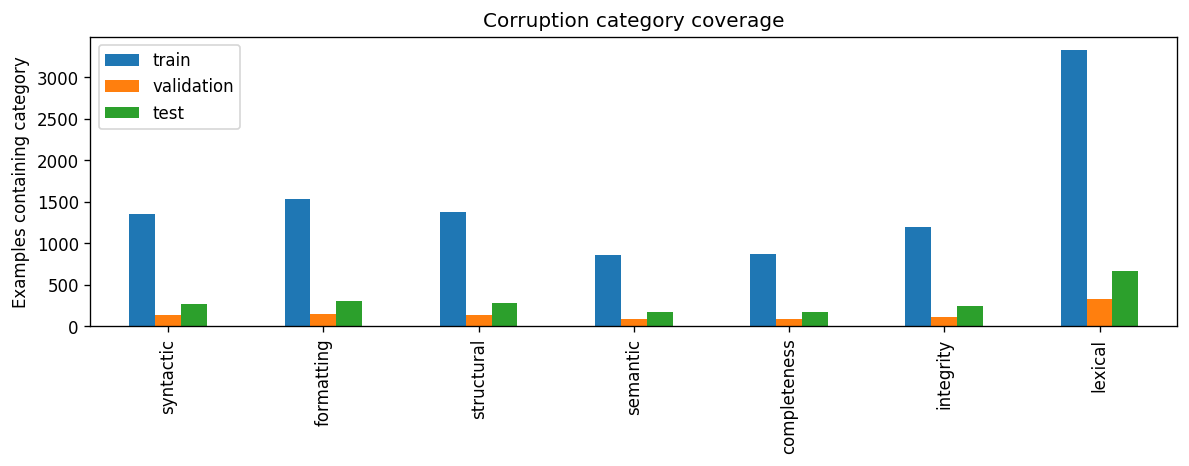

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

coverage = pd.DataFrame({split: details["categories"] for split, details in manifest["splits"].items()}).fillna(0).astype(int)
display(coverage)
coverage.plot.bar(figsize=(10, 4), title="Corruption category coverage")
plt.ylabel("Examples containing category")
plt.tight_layout()
plt.show()
print("Training composition sizes:", manifest["splits"]["train"]["composition_sizes"])
print(json.dumps(data["train"][35], indent=2))


### Original and corrupted data samples

The following tables show the first, middle, and last **20 rows** of the original
CSV and **20 examples** from the synthetic dataset. Synthetic JSONL rows each
contain a complete four-candle window; the raw CSV remains visible, including
malformed structure. The synthetic view concatenates train, validation, then test
in their saved order and shows the split and instruction label for each example.
These inspection tables are separate from the model prompt.


In [4]:
from html import escape
from IPython.display import HTML

def show_data_samples(frame, title, raw_csv=False):
    count = 20
    middle_start = max(0, len(frame) // 2 - count // 2)
    starts = [("First", 0), ("Middle", middle_start), ("Last", max(0, len(frame) - count))]
    for label, start in starts:
        sample = frame.iloc[start:start + count]
        display(HTML(f"<h3>{escape(title)} — {label.lower()} 20 rows</h3>"
                     f"<p>Rows {start + 1:,}–{start + len(sample):,} of {len(frame):,}.</p>"))
        table = sample.style.format(escape="html").hide(axis="index")
        if raw_csv:
            table = table.set_properties(subset=["input"], **{
                "white-space": "pre-wrap", "font-family": "monospace",
                "text-align": "left", "min-width": "600px"})
        display(table.set_table_attributes('style="display:block;overflow-x:auto"'))

original_view = pd.read_csv(SOURCE, dtype=str, keep_default_na=False)
original_view.insert(0, "source_row", range(1, len(original_view) + 1))
show_data_samples(original_view, "Original candle data")

synthetic_rows = []
for split in ("train", "validation", "test"):
    for record in data[split]:
        synthetic_rows.append({"dataset_row": len(synthetic_rows) + 1, "split": split,
                               "id": record["id"], "input": record["input"],
                               "recoverable": record["target"]["recoverable"],
                               "operations": json.dumps(record["target"]["operations"])})
synthetic_view = pd.DataFrame(synthetic_rows)
show_data_samples(synthetic_view, "Corrupted synthetic dataset", raw_csv=True)


source_row,time,open,high,low,close,Volume,ROC
1,2007-03-12T22:00:00-06:00,650.5,651.25,648.6,649.8,2307,
2,2007-03-13T04:00:00-06:00,649.6,652.3,646.5,649.1,13549,
3,2007-03-13T10:00:00-06:00,648.95,649.65,641.6,643.55,6099,
4,2007-03-13T16:00:00-06:00,643.4,644.3,639.95,641,2209,
5,2007-03-13T22:00:00-06:00,640.95,643.35,639.85,642.85,2605,
6,2007-03-14T04:00:00-06:00,642.45,645.95,638.5,641.6,17117,
7,2007-03-14T10:00:00-06:00,641.5,645.2,636.13,644.45,8875,
8,2007-03-14T16:00:00-06:00,643.45,646.6,643,644.75,1757,
9,2007-03-14T22:00:00-06:00,644.65,647.35,643.45,646.85,2304,
10,2007-03-15T04:00:00-06:00,647.05,650.3,643.45,648.4,13487,


source_row,time,open,high,low,close,Volume,ROC
10156,2017-01-06T04:00:00-07:00,1179.06,1182.92,1170.9,1173.25,479272,-1.2738646510030545
10157,2017-01-06T10:00:00-07:00,1173.16,1174.87,1170.7,1172.13,193097,-1.1392700104416997
10158,2017-01-08T16:00:00-07:00,1172.57,1176.58,1171.59,1174.51,159403,-1.0120285518576273
10159,2017-01-08T22:00:00-07:00,1174.54,1178.65,1172.7,1176.7,264807,-0.8734347923255711
10160,2017-01-09T04:00:00-07:00,1176.75,1183.96,1176.3,1183.17,412540,-0.7333689161793
10161,2017-01-09T10:00:00-07:00,1183.12,1186.19,1180.11,1180.9,167254,-0.5996188407904448
10162,2017-01-09T16:00:00-07:00,1181.12,1187.22,1179.9,1184.6,237868,-0.46902753672528147
10163,2017-01-09T22:00:00-07:00,1184.68,1187.64,1182.5,1185.34,279373,-0.3313103607884892
10164,2017-01-10T04:00:00-07:00,1185.37,1190.61,1180.8,1187.92,439058,-0.1852483024343759
10165,2017-01-10T10:00:00-07:00,1187.89,1188.73,1181.8,1187.5,206524,-0.04021875924997048


source_row,time,open,high,low,close,Volume,ROC
20311,2026-11-08T16:00:00-07:00,4069.99,4134.18,4054.08,4124.13,930820,-2.893196904323401
20312,2026-11-08T22:00:00-07:00,4123.68,4126.981,4084.4,4098.36,802927,-2.82546811608173
20313,2026-11-09T04:00:00-07:00,4098.447,4130.871,4097.4,4110.3,965696,-2.746469086251419
20314,2026-11-09T10:00:00-07:00,4110.42,4148.6,4099.8,4140.021,636004,-2.648486075639802
20315,2026-11-09T16:00:00-07:00,4140.93,4146.696,4107.5,4114.67,752939,-2.5812782672917742
20316,2026-11-09T22:00:00-07:00,4114.95,4127.93,4072.1,4074.89,828257,-2.5505944094014
20317,2026-11-10T04:00:00-07:00,4074.83,4079.737,4013.2,4022.11,1044128,-2.5256892779209803
20318,2026-11-10T10:00:00-07:00,4022.121,4036.84,4014.3,4032.031,600281,-2.491244016085017
20319,2026-11-10T16:00:00-07:00,4032.62,4052.641,4025.9,4046.288,693075,-2.4217369668205846
20320,2026-11-10T22:00:00-07:00,4046.288,4066.928,4044.3,4050.828,728114,-2.3313627527096252


dataset_row,split,id,input,recoverable,operations
1,train,train-000001,"time,open,high,low,close,Volume,ROC 2008-12-18T10:00:00-07:00,852.1,860.8,851.05,852.05,17780,4.044330548000394 2008-12-18T16:00:00-07:00,851.7,854.5,844.45,850.1,4399,4.21625969578072 2008-12-18T22:00:00-07:00,850.05,853.8,836.75,837.9,13550,4.3598717643959795 2008-12-19T04:00:00-07:00,838.02,841.7,829.1,838.5,62000,4.480240530780261",False,[]
2,train,train-000002,"time,open,high,low,close,Volume,ROC 2018-02-22T10:00:00-07:00,1329.349,1332.2,1328.38,1331.65,323296,-0.10123463347927408 2018-02-22T16:00:00-07:00,1331.1,1332.2,1326.54,1327.126,304197,-0.11698113452365727 2018-02-22T22:00:00-07:00,1327.12,1329.796,1325.5,1328.65,362919,-0.13746958505369095 2018-02-23T04:00:00-07:00,1328.75,1331.616,1326.5,1328722,520622,-0.16421264167942742",False,[]
3,train,train-000003,"time,open,high,low,close,Volume,ROC 2007-11-06T10:00:00-07:00,822.65,825.05,819.15,824.6,10366,5.112404537201593 2007-11-06T16:00:00-07:00,823.65,836.4,822.25,834.1,9455,5.23903818705784 2007-11-06T22:00:00-07:00,834.1,845.75,832.4,841.85,13861,5.376886396523592 2007-11-07T04:00:00-07:00,841.8,843.6,827.9,83.63,47894,5.482969412335156",False,[]
4,train,train-000004,"time,open,high,low,close,Volume,ROC 2008-03-06T10:00:00-07:00,973.65,979.25,964.55,978.6,16771,5.14605435289358 2008-03-06T16:00:00-07:00,975.95,983.9,975.2,981.7,47@29,5.25039275710031 2008-03-06T22:00:00-07:00,982,985,976.3,977.5,10406,5.33470457268637 2008-03-07T04:00:00-07:00,977.25,988.65,969.5,970.6,47765,5.382794518539027",True,"[""remove_extraneous_characters""]"
5,train,train-000005,"time,open,high,low,close,Volume,ROC 2012-03-20T04:00:00-06:00,1649.3,1657.93,1641.3,1652.44,148388,-3.2850674609067245 2012-03-20T10:00:00-06:00,1652.35,1655.75,1644.05,1650.52,8009~4,-3.303015073918654 2012-03-20T16:00:00-06:00,1651.1,1656.61,1647.4,1652.49,47190,-3.3208597807746942 2012-03-20T22:00:00-06:00,1652.4,1660.18,1648.45,1655.6,71959,-3.32948142559667",True,"[""remove_extraneous_characters""]"
6,train,train-000006,"time,open,high,low,close,Volume,ROC 2015-01-22T16:00:00-07:00,1301.34,1302.65,1296.1,1297,134951,4.7217515165888635 2015-01-22T22:00:00-07:00,1297.12,1297.5,1292.5,1294.7,216407,4.806431714546791 2015-01-23T04:00:00-07:00,1294.65,1299..75,1284.2,1290.62,320339,4.871146309714551 2015-01-23T10:00:00-07:00,1290.62,1295.28,1288.42,1294.08,114086,4.932147250766919",True,"[""repair_numeric_punctuation""]"
7,train,train-000007,"time,open,high,low,close,Volume,ROC 2019-11-15T10:00:00-07:00,1466.018,1468.36,1465.6,1467.792,108761,-1.1105431387204339 2019-11-17T16:00:00-07:00,1467.279,1469.6,1464.78,1466.228,121372,$-1.1270133671285816 2019-11-17T22:00:00-07:00,1466.19,1466.39,1457.28,1457.9,240862,-1.1530371475507668 2019-11-18T04:00:00-07:00,1457.94,1473.95,1456.24,1470.99,444610,-1.1540334769211373",True,"[""normalize_numeric_format""]"
8,train,train-000008,"time,open,high,low,close,Volume,ROC 2019-01-21T10:00:00-07:00,1280.426,1280.71,1279.5,1280.05 USD,10006,1.8412677806728515 2019-01-21T16:00:00-07:00,1279.8,1280.53,1277.1,1277.63,105528,1.7660893592006162 2019-01-21T22:00:00-07:00,1277.52,1285,1277.2,1283.76,177434,1.710595028835573 2019-01-22T04:00:00-07:00,1283.75,1284.4,1278.9,1283.13,236660,1.645270909636497",True,"[""normalize_numeric_format""]"
9,train,train-000009,"time,open,high,low,close,Volume,ROC 2013-08-02T04:00:00-06:00,1287.41,1318.44,""1282,93"",1311.38,329307,2.771107086059307 2013-08-02T10:00:00-06:00,1311.18,1313.47,1307.1,1311.45,78504,2.7449060499056457 2013-08-04T16:00:00-06:00,1311.96,1320.8,1310.5,1317.2,96228,2.7264917837259923 2013-08-04T22:00:00-06:00,1316.98,1318.1,1310.01,1311.5,114624,2.689858038778348",True,"[""normalize_numeric_format""]"
10,train,train-000010,"time,open,high,low,close,Volume,ROC 2020-12-11T04:00:00-07:00,1832,1847.75,1822.62,1842.344,521779,-2.062685443454812 2020-12-11T10:00:00-07:00,1842.38,1843.3,1836.6,1838.998,156596,-1.9598874572873146 2020-12-13T16:00:00-07:00,1.84071

dataset_row,split,id,input,recoverable,operations
6491,train,train-006491,"time,open,high,low,close,Volume,ROC 2011-03-02T04:00:00-07:00,1433.3,1440.45,1431.15,1439.33,74259,3.1234015826823036 2011-03-02T04:00:00-07:00,1439.39,1439.75,1429.83,1433.8,29746,3.1968248507023893 2011-03-02T16:00:00-07:00,1436.1,1436.1,1430.8,1435.2,9314,3.265864187783531 2011-03-02T22:00:00-07:00,1435.3,1436.2,1422.3,1427.94,29122,3.3263602407252186",False,[]
6492,train,train-006492,"time,open,high,low,close,Volume,ROC 2020-11-04T04:00:00-07:00,1889.25,1912.23,1886.8,1901.425,691223,-0.3776747104816518 2020-11-04T16:00:00-07:00,1902.847,1909.694,1901.987,1906.18,256179,-0.35446888211338035 2020-11-04T22:00:00-07:00,1906.19,1919.14,1904.8,1918.134,413969,-0.31266603338508303",False,[]
6493,train,train-006493,"time,open,high,low,close,Volume,ROC 2017-10-31T04:00:00-06:00,1275.54,1275.69,1267.54,1269.7,446995,-0.6365051529650178 2017-10-30T22:00:00-06:00,1275.66,1278.14,1274.6,1275.46,269228,-0.5953268879316452 2017-10-30T10:00:00-06:00,1274.38,1278.9,1274,1276.3,268546,-0.5623655156036129 2017-10-30T16:00:00-06:00,1275.9,1277.5,1274.7,1275.66,212420,-0.5745874859997668",True,"[""sort_chronologically""]"
6494,train,train-006494,"time,open,high,low,close,Volume,ROC 2010-06-22T22:00:00-06:00,1240.3,1244.2,1237.85,1242.82,18663,1.9099597472020562 2010-06-22T16:00:00-06:00,1239.37,1241.45,1237.05,1240.28,7278,1.8754781950302604 2010-06-22T10:00:00-06:00,1236.35,1241.6,1235.95,1239.85,25752,1.8584045245754193 2010-06-22T04:00:00-06:00,1234.7,1242.75,1231.83,1236.28,64354,1.8610962905510589",True,"[""sort_chronologically""]"
6495,train,train-006495,"time,open,high,low,close,Volume,ROC 2007-12-31T10:00:00-07:00,832.6,834.7,831.55,833.3,976,1.5496628721112888 2007-12-31T16:00:00-07:00,833.3,833.3,832.85,832.85,53,1.5744178041383061 2007-12-31T22:00:00-07:00,833.3,833.3,832.85,832.85,47,1.5999358989022192 2008-01-01T04:00:00-07:00,833.3,833.3,832.25,833.3,forty-six,1.6336609140159688",True,"[""parse_number_words""]"
6496,train,train-006496,"time,open,high,low,close,Volume,ROC 2012-01-24T04:00:00-07:00,1668.95,1670.7,1661.2,1667.2,121852,2.0808959240066227 2012-01-24T10:00:00-07:00,one thousand six hundred sixty-seven point two five US dollars,1669.95,1662.3,1664.8,49086,2.1174885925705356 2012-01-24T16:00:00-07:00,1664.97,1668.45,1664.1,1665.95,31261,2.159725638715304 2012-01-24T22:00:00-07:00,1665.92,1670.2,1652.9,1655.06,56820,2.1550793413848863",True,"[""parse_currency_words""]"
6497,train,train-006497,"time,open,high,low,close,Volume,ROC 2020-12-04T04:00:00-07:00,1839.63,1848.21,1828.9,1833.25,603890,-3.0397667763977094 2020-12-04T10:00:00-07:00,1833.11,1839.37,1831.3,1838.208,one hundred forty-nine thousand one hundred eighty-five,-3.028388619359968 2020-12-06T16:00:00-07:00,1837.678,1839.75,1832.7,1838.884,196366,-3.0121140470320436 2020-12-06T22:00:00-07:00,1838.95,1842.4,1821.47,1831.664,324784,-2.9979439883288452",True,"[""parse_number_words""]"
6498,train,train-006498,"time,open,high,low,close,Volume,ROC 2020-07-01T10:00:00-06:00,1766.81,1773.28,1765,1769.598,three hundred four thousand forty-four,1.958355482978772 2020-07-01T16:00:00-06:00,1769.758,1772.27,1765.5,1768.83,117422,1.9599743531058305 2020-07-01T22:00:00-06:00,1768.5,1773.346,1764.09,1772.924,195081,1.976502500215418 2020-07-02T04:00:00-06:00,1772.88,1779.62,1757.39,1778.04,481660,2.0025290976201244",True,"[""parse_number_words""]"
6499,train,train-006499,"time,open,high,low,close,Volume,ROC 2007-11-09T10:00:00-07:00,831.75,833.65,830.15,831.6,6295,6.547278358595952 2007-11-11T16:00:00-07:00,831.7,831.7,815.7,816.9,9558,6.584616177900912 2007-11-11T22:00:00-07:00,816.85,820.75,813.35,817.95,11880,6.619000833707706 2007-11-12T04:00:00-07:00,818,818.45,seven hundred ninety-seven point 1,801.35,23315,6.586647435978365",True,"[""parse_mixed_number_expression""]"
6500,train,train-006500,"time,open,high,low,close,Volume,ROC 2017-10-17T10:00:00-06:00,1284.24,1287.48,1283.7,1285.1,229120,-1.1832

dataset_row,split,id,input,recoverable,operations
12981,test,test-001981,"time,open,high,low,close,Volume,ROC 2024-05-21T22:00:00-06:00,2414.1,2418.5,2410.2,2417.145,307316,1.9640957066178617 2024-05-22T04:00:00-06:00,2417.21,2419.381,2381.8,2391.928,552990,2.021986454641674 2024-05-22T10:00:00-06:00,2391.918,2395.09,2374.5,2378.506,293882,2.0616582102685164 2024-05-22T16:00:00-06:00,2380.711,2383.7,2366.3,2372.42,252488,2.102772275359154",False,[]
12982,test,test-001982,"open,high,low,close,Volume,ROC 1939.62,1945.69,1933.9,1943.99,242055,3.0894806706149107 1943.96,1951.91,1936.6,1947.224,371715,3.175134114660563 1947.24,1978.78,1944.775,1969.5,415011,3.280430349191646 1969.714,1977.64,1964.38,1976.6,228928,3.392634705396946",False,[]
12983,test,test-001983,"time,open,high,low,close,Volume,ROC 2025-06-01T22:00:00-06:00,3308.61,3359.067,3308.425,3348.35,444427,0.15640746821266624 2025-06-02T04:00:00-06:00,3348.26,3378.85,3344.298,3374.38,625433,0.28649252430907995 2025-06-02T10:00:00-06:00,3374.2,3382.89,3368.975,3381.165,322821,0.41543565167138646 2025-06-02T16:00:00-06:00,3381.38,3392.1,3359.445,3361.103,437160,0.5682010442887512 2025-06-02T16:00:00-06:00,3381.38,3392.1,3359.445,3361.103,437160,0.5682010442887512",True,"[""deduplicate_records""]"
12984,test,test-001984,"time,open,high,low,close,Volume,ROC 2026-08-23T22:00:00-06:00,4641.54,4659.96,4628.46,4645.58,745784,7.347927493094795 2026-08-24T04:00:00-06:00,4645.97,4680.92,4638.84,4649.068,944021,7.509902925035978 2026-08-24T10:00:00-06:00,4643.2,4662.48,4624.91,4651.753,596336,7.644995954629704 2026-08-24T10:00:00-06:00,4649.2,4662.48,4624.91,4651.753,596336,7.644995954629704 2026-08-24T16:00:00-06:00,4654.46,4697.07,4617.46,4633.56,760073,7.702476408785318",False,[]
12985,test,test-001985,"time,open,high,low,close,Volume,ROC 2024-06-30T22:00:00-06:00,2324.691,2329.51,2318.1,2327.39,299065,-0.5093398012746955 2024-06-30T22:00:00-06:00,2327.371,2338.55,2318.8,2327.698,487008,-0.47617769541426547 2024-07-01T10:00:00-06:00,2327.74,2332.4,2326.4,2331.485,180668,-0.43914877692456317 2024-07-01T16:00:00-06:00,2330.848,2334.36,2325.5,2326.01,145278,-0.438123115512639",False,[]
12986,test,test-001986,"time,open,high,low,close,Volume,ROC 2024-03-05T10:00:00-07:00,2128.293,2134.74,2126.7,2127.625,185866,1.3277722463218664 2024-03-04T22:00:00-07:00,2116.02,2127.35,2113.5,2123.67,240705,0.9906917974240175 2024-03-05T16:00:00-07:00,2127.703,2128.5,2123.2,2126.119,106657,1.4767616504913568 2024-03-05T04:00:00-07:00,2123.673,2141.81,2121,2128.3,514404,1.1652477293219186",True,"[""sort_chronologically""]"
12987,test,test-001987,"time,open,high,low,close,Volume,ROC 2025-07-14T16:00:00-06:00,3342.817,3358.37,3341.125,3357.843,194580,-0.5846044338979633 2025-07-14T10:00:00-06:00,3345.04,3351.68,3341.105,3342.785,248330,-0.6327316918884749 2025-07-14T04:00:00-06:00,3370.093,3374.68,3340.755,3344.925,501762,-0.6686256583385224 2025-07-13T22:00:00-06:00,3356.99,3374.96,3353.435,3370.16,349836,-0.7047383181926651",True,"[""sort_chronologically""]"
12988,test,test-001988,"time,open,high,low,close,Volume,ROC 2023-09-28T22:00:00-06:00,1863.25,1873.97,1862.7,1873.551,184358,-0.7866145334507519 2023-09-29T04:00:00-06:00,1873.59,1879.81,1852,1854.73,428616,-0.8696648992468631 2023-09-29T10:00:00-06:00,1854.73,1856.48,1845.9,1848.1,188787,-0.9549664050470833 2023-10-01T16:00:00-06:00,1848.1,1849.96,1842.5,1843.437,102584,minus one point zero three four eight seven nine three three three seven three five five zero nine three",True,"[""parse_number_words""]"
12989,test,test-001989,"time,open,high,low,close,Volume,ROC 2026-09-13T22:00:00-06:00,4330.32,4338.663,four thousand two hundred seventy-eight point two four US dollars,4285.526,707795,-0.1563518942565129 2026-09-14T04:00:00-06:00,4285.475,4298.328,4252.7,4288.251,887028,-0.3943393484469657 2026-09-14T10:00:00-06:00,4288.175,4317.79,4281.6,4298.46,542048,-0.6041861136718599 2026-09-14T16:00:00-06:00,4298.32,4317.37,4283.04,4303.31,542456,-0.78537

## 4. Score JSON instructions without tools

Recoverability accuracy credits a parseable Boolean independently of operation
correctness. Operation-sequence accuracy uses only oracle-positive examples as
its denominator. Full-answer accuracy requires strictly valid JSON matching the
whole reference; format validity checks the full contract. Invalid predictions
remain failures in every applicable denominator. No repair function is called.
The confusion matrix includes a separate invalid-prediction column.


In [5]:
from candleprep.recovery.registry import REGISTRY

KNOWN_OPERATIONS = frozenset(REGISTRY)

def strict_json(text):
    def unique_pairs(pairs):
        result = {}
        for key, value in pairs:
            if key in result:
                raise ValueError("Duplicate JSON key")
            result[key] = value
        return result
    def reject_constant(value):
        raise ValueError("Non-JSON constant: " + value)
    if not isinstance(text, str):
        return None
    try:
        value = json.loads(text, object_pairs_hook=unique_pairs, parse_constant=reject_constant)
    except (ValueError, TypeError, RecursionError):
        return None
    return value if isinstance(value, dict) else None

def score_prediction(prediction, reference):
    value = strict_json(prediction)
    decision = value.get("recoverable") if value is not None else None
    decision_valid = type(decision) is bool
    operations = value.get("operations") if value is not None else None
    operations_valid = type(operations) is list and all(type(name) is str and name in KNOWN_OPERATIONS for name in operations)
    valid = (value is not None and set(value) == {"recoverable", "operations"}
             and decision_valid and operations_valid and (decision or not operations))
    return {
        "recoverability_correct": decision_valid and decision == reference["recoverable"],
        "operation_sequence_correct": operations_valid and operations == reference["operations"],
        "full_answer_correct": bool(valid and value == reference),
        "format_valid": bool(valid),
        "predicted_class": str(decision).lower() if decision_valid else "invalid",
    }

def score_predictions(predictions, records):
    if len(predictions) != len(records) or not records:
        raise ValueError("Need one prediction per reference and a nonempty dataset")
    counts = Counter()
    confusion = {"false": {"false": 0, "true": 0, "invalid": 0},
                 "true": {"false": 0, "true": 0, "invalid": 0}}
    for prediction, record in zip(predictions, records):
        reference = record["target"]
        result = score_prediction(prediction, reference)
        counts["recoverability"] += int(result["recoverability_correct"])
        counts["full_answer"] += int(result["full_answer_correct"])
        counts["format"] += int(result["format_valid"])
        if reference["recoverable"]:
            counts["positive"] += 1
            counts["sequence"] += int(result["operation_sequence_correct"])
        confusion[str(reference["recoverable"]).lower()][result["predicted_class"]] += 1
    return {
        "examples": len(records), "oracle_positive_examples": counts["positive"],
        "recoverability_accuracy": counts["recoverability"] / len(records),
        "operation_sequence_accuracy": counts["sequence"] / counts["positive"] if counts["positive"] else None,
        "full_answer_accuracy": counts["full_answer"] / len(records),
        "format_validity": counts["format"] / len(records), "confusion_matrix": confusion,
    }

def score_breakdowns(predictions, records, references):
    if len(references) != len(records) or any(a["id"] != b["id"] for a, b in zip(records, references)):
        raise ValueError("Evaluation metadata must match record IDs")
    groups = {}
    for index, reference in enumerate(references):
        names = list(reference["categories"])
        names.append("single" if reference["composition_size"] == 1 else "composed")
        for name in names:
            groups.setdefault(name, []).append(index)
    output = {}
    for name, indices in groups.items():
        output[name] = score_predictions([predictions[i] for i in indices], [records[i] for i in indices])
    return output


## 5. Fixed model-visible task and response boundary

Use the model's chat template rather than manually splitting decoded prompts.
Prompts contain no source IDs, categories, histories, originals, or reference
targets. The registry names and supported conventions are static instructions.
Labels and padding are the only supervised tokens; prompts receive label -100.
Long samples raise an error rather than truncating the answer.


In [6]:
TASK = """Given a corrupted candle CSV window, predict the canonical shortest repair plan under the supported tools.
Return only JSON with exactly two keys: recoverable (a Boolean) and operations (an ordered list of tool names).
Use {"recoverable":false,"operations":[]} when exact recovery of the complete window is unsupported. The complete window is omitted in that case.
Schema: time,open,high,low,close,Volume,ROC. All fields are required except ROC, which may be blank. Negative ROC is valid.
Timestamps require an explicit UTC offset. Irregular market intervals are allowed. Preserve all rows and exact numeric meaning.
Supported conventions: English cardinal words and individual fractional digits; minus for negatives; point or normalized decimal;
USD currency words; currency prefix $; suffixes USD/contracts/percent; decimal comma without thousands grouping;
cents explicitly identify a scale of 100; declared removable noise is ? @ ~; doubled decimal punctuation;
alternate date DD/MM/YYYY HH:MM:SS followed by numeric UTC offset; column headers move with column values;
cyclic row rotations identifiable by time; exact timestamp-identical duplicates; chronological row sorting.
Arbitrary digit/sign changes, lost decimals/digits, missing required values, conflicting duplicates, and missing rows are unsupported.
Operation names: """ + ", ".join(sorted(KNOWN_OPERATIONS)) + """.
Do not include unnecessary validator calls. Valid data needing no transforms uses recoverable true and an empty operations list.
Corrupted CSV:
"""

def user_text(record):
    return TASK + record["input"]

def prompt_tokens(tokenizer, record):
    return tokenizer.apply_chat_template([{"role": "user", "content": user_text(record)}], tokenize=True, add_generation_prompt=True, return_dict=False)

def tokenize_record(record, tokenizer):
    messages = [{"role": "user", "content": user_text(record)}]
    prompt = prompt_tokens(tokenizer, record)
    target = json.dumps(record["target"], separators=(",", ":"))
    full = tokenizer.apply_chat_template(messages + [{"role": "assistant", "content": target}], tokenize=True, return_dict=False)
    if full[:len(prompt)] != prompt:
        raise ValueError("Chat template does not preserve the prompt boundary")
    if len(full) > MAX_LENGTH:
        raise ValueError(f"Sample {record['id']} needs {len(full)} tokens; increase MAX_LENGTH without dropping its target")
    return {"input_ids": full, "attention_mask": [1] * len(full),
            "labels": [-100] * len(prompt) + full[len(prompt):]}


## 6. Prepare the starter's quantized Mistral/PEFT framework

This retains Transformers Trainer, PEFT-LoRA, 4-bit NF4/double quantization,
and the starter's Mistral-7B model. Each rank reloads a fresh base. Batch size 1,
gradient accumulation, and checkpointing target the 24 GB budget. No model is
loaded while all GPU switches are false. Existing medical adapters are unused.


In [7]:
import torch
from datasets import Dataset
from transformers import (AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig,
                          DataCollatorForSeq2Seq, Trainer, TrainingArguments, set_seed)
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training

def load_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    return tokenizer

def require_gpu():
    if not torch.cuda.is_available():
        raise RuntimeError("A CUDA GPU is required for the model stages")
    free, total = torch.cuda.mem_get_info()
    if free < 12 * 1024**3:
        raise RuntimeError("Less than 12 GiB GPU memory is free. Release the previous model in its kernel before this run.")
    print(torch.cuda.get_device_name(), "free GiB:", round(free / 1024**3, 2))

def load_base():
    require_gpu()
    set_seed(SEED)
    compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    quantization = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                     bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=compute_dtype)
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=quantization,
                                               device_map={"": 0}, attn_implementation="sdpa")

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2) + "\n", encoding="utf-8")

def save_records(path, records):
    with Path(path).open("w", encoding="utf-8") as stream:
        for record in records:
            stream.write(json.dumps(record) + "\n")

def predict(model, tokenizer, records):
    model.eval()
    model.config.use_cache = True
    predictions = []
    for index, record in enumerate(records):
        ids = prompt_tokens(tokenizer, record)
        if len(ids) + MAX_NEW_TOKENS > MAX_LENGTH:
            raise ValueError("Prompt exceeds the frozen generation budget")
        inputs = torch.tensor([ids], device=model.get_input_embeddings().weight.device)
        with torch.inference_mode():
            generated = model.generate(input_ids=inputs, attention_mask=torch.ones_like(inputs),
                                       max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                                       pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
        predictions.append(tokenizer.decode(generated[0, inputs.shape[1]:], skip_special_tokens=True).strip())
        if (index + 1) % 100 == 0:
            print("Predictions:", index + 1, "/", len(records))
    return predictions

def evaluate_and_save(model, tokenizer, split, label, output_dir=RESULTS):
    predictions = predict(model, tokenizer, data[split])
    report = score_predictions(predictions, data[split])
    report["breakdowns"] = score_breakdowns(predictions, data[split], metadata[split])
    saved = []
    for record, prediction in zip(data[split], predictions):
        saved.append({"id": record["id"], "prediction": prediction, "reference": record["target"]})
    save_records(output_dir / (label + "_" + split + "_predictions.jsonl"), saved)
    save_json(output_dir / (label + "_" + split + "_metrics.json"), report)
    return report

def run_environment():
    from importlib.metadata import version
    return {"platform": platform.platform(), "python": platform.python_version(),
            "gpu": torch.cuda.get_device_name(), "model": MODEL_ID, "seed": SEED,
            "max_length": MAX_LENGTH, "max_new_tokens": MAX_NEW_TOKENS,
            "prompt_sha256": hashlib.sha256(TASK.encode()).hexdigest(),
            "dataset_artifacts": manifest["artifact_sha256"],
            "packages": {name: version(name) for name in ("torch", "transformers", "datasets", "peft", "bitsandbytes")}}

def release_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


## 7. Tiny GPU smoke run and adapter reload

The smoke run draws from a 16-example preview for two optimizer steps (eight
examples processed with batch size 1 and accumulation 4). It verifies finite
loss, trainable parameters, adapter files, and a finite forward loss after loading
that adapter onto a fresh base. This is a compatibility check, not evidence of
task improvement. Full rank experiments require this checkpoint to pass first.


In [8]:
def train_adapter(rank, destination, smoke=False):
    if destination.exists():
        raise FileExistsError("Choose a new results directory; this run already exists: " + str(destination))
    tokenizer = load_tokenizer()
    model = load_base()
    model = prepare_model_for_kbit_training(model)
    config = LoraConfig(r=rank, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                        target_modules=["q_proj", "v_proj", "k_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(model, config)
    model.config.use_cache = False
    model.print_trainable_parameters()
    assert any(parameter.requires_grad for parameter in model.parameters())
    examples = data["train"][:16] if smoke else data["train"]
    tokenized = Dataset.from_list([tokenize_record(record, tokenizer) for record in examples])
    arguments = TrainingArguments(
        output_dir=str(destination), per_device_train_batch_size=1,
        gradient_accumulation_steps=4 if smoke else 16,
        max_steps=2 if smoke else -1, num_train_epochs=1,
        learning_rate=2e-4, logging_steps=1 if smoke else 25,
        optim="paged_adamw_8bit", bf16=torch.cuda.is_bf16_supported(),
        fp16=not torch.cuda.is_bf16_supported(), gradient_checkpointing=True,
        save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
        remove_unused_columns=False)
    trainer = Trainer(model=model, args=arguments, train_dataset=tokenized,
                      processing_class=tokenizer,
                      data_collator=DataCollatorForSeq2Seq(tokenizer, pad_to_multiple_of=8, label_pad_token_id=-100))
    torch.cuda.reset_peak_memory_stats()
    result = trainer.train()
    if not math.isfinite(result.training_loss):
        raise RuntimeError("Training loss is not finite")
    adapter_dir = destination / "adapter"
    trainer.model.save_pretrained(adapter_dir)
    tokenizer.save_pretrained(adapter_dir)
    trainer.state.save_to_json(str(destination / "trainer_state.json"))
    save_json(destination / "training.json", {"rank": rank, "lora_alpha": 32, "learning_rate": 2e-4,
              "configured_epochs": 1, "completed_epochs": trainer.state.epoch,
              "optimizer_steps": trainer.state.global_step,
              "training_examples_available": len(examples),
              "per_device_train_batch_size": arguments.per_device_train_batch_size,
              "gradient_accumulation_steps": arguments.gradient_accumulation_steps,
              "smoke": smoke, "training_loss": result.training_loss,
              "peak_allocated_gib": torch.cuda.max_memory_allocated() / 1024**3,
              "environment": run_environment()})
    del trainer, model
    release_gpu()
    return adapter_dir

if RUN_GPU_SMOKE:
    smoke_adapter = train_adapter(8, RESULTS / "smoke", smoke=True)
    smoke_tokenizer = load_tokenizer()
    smoke_model = PeftModel.from_pretrained(load_base(), smoke_adapter)
    smoke_model.eval()
    batch = DataCollatorForSeq2Seq(smoke_tokenizer, label_pad_token_id=-100)([tokenize_record(data["train"][0], smoke_tokenizer)])
    batch = {key: value.to(smoke_model.get_input_embeddings().weight.device) for key, value in batch.items()}
    with torch.inference_mode():
        reload_loss = float(smoke_model(**batch).loss)
    assert math.isfinite(reload_loss)
    smoke_prediction = predict(smoke_model, smoke_tokenizer, data["validation"][:1])[0]
    print(smoke_prediction)
    save_json(RESULTS / "smoke_passed.json", {"reload_loss": reload_loss,
              "sample_prediction": smoke_prediction,
              "sample_reference": data["validation"][0]["target"],
              "sample_metrics": score_prediction(smoke_prediction, data["validation"][0]["target"]),
              "environment": run_environment()})
    del smoke_model, batch
    release_gpu()
else:
    print("New GPU smoke execution is disabled; saved results are shown below when available.")


New GPU smoke execution is disabled; saved results are shown below when available.


### Saved brief GPU experiment

Display the saved smoke-check evidence if that explicit experiment has been run.
The check uses only two optimizer steps, then reloads the adapter and generates
one response. Its loss and sample output establish execution, not general task
improvement. Full baseline, rank, and held-out test runs remain separate switches.


In [9]:
smoke_report_path = RESULTS / "smoke_passed.json"
if smoke_report_path.exists():
    smoke_report = json.loads(smoke_report_path.read_text(encoding="utf-8"))
    smoke_training = json.loads((RESULTS / "smoke/training.json").read_text(encoding="utf-8"))
    display({"training_loss": smoke_training["training_loss"],
             "reload_loss": smoke_report["reload_loss"],
             "peak_allocated_gib": smoke_training["peak_allocated_gib"],
             "elapsed_seconds": smoke_report.get("elapsed_seconds"),
             "sample_prediction": smoke_report.get("sample_prediction"),
             "sample_reference": smoke_report.get("sample_reference"),
             "sample_metrics": smoke_report.get("sample_metrics")})
else:
    print("No saved GPU smoke experiment is available yet.")


{'training_loss': 1.843063086271286, 'reload_loss': 0.20409440994262695, 'peak_allocated_gib': 5.589294910430908, 'elapsed_seconds': 59.97, 'sample_prediction': '{"recoverable":true,"operations":["normalize_numeric_format"]}', 'sample_reference': {'recoverable': False, 'operations': []}, 'sample_metrics': {'recoverability_correct': False, 'operation_sequence_correct': False, 'full_answer_correct': False, 'format_valid': True, 'predicted_class': 'true'}}

## 8. Measure the base deficit on validation data

Save the base model's predictions and all four instruction metrics. Inspect
these results before investing in rank experiments. No recovery tools execute.
The final held-out test set is reserved for the final comparison.


In [10]:
if RUN_BASELINE:
    tokenizer = load_tokenizer()
    base_model = load_base()
    base_validation = evaluate_and_save(base_model, tokenizer, "validation", "base")
    save_json(RESULTS / "environment.json", run_environment())
    display(base_validation)
    del base_model
    release_gpu()
else:
    print("Base-model deficit has not yet been measured.")


Base-model deficit has not yet been measured.


## 9. Compare LoRA ranks using validation only

Try ranks 8, 16, and 32 with the same data, seed, alpha, learning rate, effective
batch size, and epoch count. Alpha is held at 32, so effective LoRA scaling
alpha/r also changes with rank; report this limitation. Start every run from the
original base. Select the best full-answer validation accuracy, then sequence
accuracy, breaking ties in favor of the smaller rank. The test set does not
participate. Record the actual impact below after the runs finish.

**Rank findings:** Pending GPU experiments. Do not claim improvement yet.


In [11]:
if RUN_RANKS:
    if not (RESULTS / "smoke_passed.json").exists() or not (RESULTS / "base_validation_metrics.json").exists():
        raise RuntimeError("Run the smoke check and measure the base deficit first")
    rank_reports = []
    for rank in RANKS:
        adapter = train_adapter(rank, RESULTS / ("rank_" + str(rank)))
        tokenizer = load_tokenizer()
        model = PeftModel.from_pretrained(load_base(), adapter)
        report = evaluate_and_save(model, tokenizer, "validation", "rank_" + str(rank))
        rank_reports.append({"rank": rank, **report})
        del model
        release_gpu()
    selected = max(rank_reports, key=lambda report: (report["full_answer_accuracy"], report["operation_sequence_accuracy"], -report["rank"]))
    save_json(RESULTS / "rank_comparison.json", rank_reports)
    save_json(RESULTS / "selection.json", {"rank": selected["rank"], "selected_using": "validation full-answer accuracy, sequence accuracy, smaller rank"})
    display(pd.DataFrame(rank_reports).drop(columns=["breakdowns", "confusion_matrix"]))
else:
    print("Rank experiments have not been run.")


Rank experiments have not been run.


## 10. Final before/after test comparison

After selecting the adapter on validation, evaluate a fresh base and the selected
adapter on the same 2,000 held-out examples. Save all responses and breakdowns.
Use a fresh RESULTS directory for TAMU so local and A30 evidence stay separate.
Do not adjust settings after inspecting the test results.


In [12]:
if RUN_FINAL_TEST:
    selection = json.loads((RESULTS / "selection.json").read_text(encoding="utf-8"))
    tokenizer = load_tokenizer()
    model = load_base()
    evaluate_and_save(model, tokenizer, "test", "base")
    del model
    release_gpu()
    selected_adapter = RESULTS / ("rank_" + str(selection["rank"])) / "adapter"
    model = PeftModel.from_pretrained(load_base(), selected_adapter)
    evaluate_and_save(model, tokenizer, "test", "selected")
    save_json(RESULTS / "final_environment.json", run_environment())
    del model
    release_gpu()
else:
    print("Held-out model testing has not been run.")


Held-out model testing has not been run.


## 11. Present measured results

These tables and charts populate only from actual saved model metrics. They
show before/after test performance, validation rank comparisons, category and
composition breakdowns, and a binary confusion matrix with invalid outputs.


In [13]:
metric_names = ["recoverability_accuracy", "operation_sequence_accuracy", "full_answer_accuracy", "format_validity"]
test_reports = {}
for name in ("base", "selected"):
    path = RESULTS / (name + "_test_metrics.json")
    if path.exists():
        test_reports[name] = json.loads(path.read_text(encoding="utf-8"))
if len(test_reports) == 2:
    table = pd.DataFrame({name: {key: report[key] for key in metric_names} for name, report in test_reports.items()})
    display(table)
    table.plot.bar(ylim=(0, 1), figsize=(10, 4), title="Held-out instruction performance before and after LoRA")
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(test_reports["selected"]["confusion_matrix"]).T.rename_axis("Oracle class"))
    display(pd.DataFrame(test_reports["selected"]["breakdowns"]).T[metric_names])
else:
    print("No completed before/after test comparison is available.")
rank_path = RESULTS / "rank_comparison.json"
if rank_path.exists():
    rank_table = pd.DataFrame(json.loads(rank_path.read_text(encoding="utf-8"))).set_index("rank")[metric_names]
    display(rank_table)
    rank_table.plot.bar(ylim=(0, 1), title="Validation performance by LoRA rank", figsize=(10, 4))
    plt.tight_layout()
    plt.show()


No completed before/after test comparison is available.


## 12. Separate final repair execution demonstration

Only this explicitly enabled section executes model-directed tools. It consumes
saved selected-model test predictions, validates each plan, and omits complete
negative windows. Tools receive no answer key. References are consulted afterward
to score reconstruction. Repaired windows, omissions, and outcomes are saved
separately. Coverage and false omissions accompany reconstruction accuracy.


In [14]:
def final_execution_demo(records, references, saved_predictions, destination):
    from candleprep.oracle.executor import execute
    from candleprep.oracle.verifier import equivalent
    from candleprep.schema import RecoveryError
    if destination.exists():
        raise FileExistsError("Demonstration output already exists")
    if not (len(records) == len(references) == len(saved_predictions)):
        raise ValueError("Demonstration records must align")
    counts = Counter()
    repaired = []
    omissions = []
    outcomes = []
    for record, reference, saved in zip(records, references, saved_predictions):
        if not (record["id"] == reference["id"] == saved["id"]):
            raise ValueError("Demonstration IDs do not match")
        expected_positive = record["target"]["recoverable"]
        counts["oracle_recoverable"] += int(expected_positive)
        result = score_prediction(saved["prediction"], record["target"])
        plan = strict_json(saved["prediction"])
        status = "invalid_plan"
        reconstructed = False
        if result["format_valid"]:
            if not plan["recoverable"]:
                status = "omitted"
                omissions.append(record["id"])
                counts["false_omissions"] += int(expected_positive)
            else:
                counts["attempted_repairs_of_oracle_negative"] += int(not expected_positive)
                try:
                    restored = execute(record["input"], plan["operations"])
                    reconstructed = equivalent(restored, reference["original"])
                    status = "reconstructed" if reconstructed else "incorrect_reconstruction"
                    repaired.append({"id": record["id"], "csv": restored})
                    counts["retained"] += 1
                    counts["exact_on_oracle_recoverable"] += int(reconstructed and expected_positive)
                except RecoveryError:
                    status = "execution_failure"
        counts[status] += 1
        outcomes.append({"id": record["id"], "status": status, "exact_reconstruction": reconstructed})
    summary = dict(counts)
    summary["examples"] = len(records)
    summary["retained_coverage"] = counts["retained"] / len(records)
    summary["exact_reconstruction_on_oracle_recoverable"] = (counts["exact_on_oracle_recoverable"] / counts["oracle_recoverable"] if counts["oracle_recoverable"] else None)
    destination.mkdir(parents=True)
    save_records(destination / "repaired_windows.jsonl", repaired)
    save_json(destination / "omitted_example_ids.json", omissions)
    save_records(destination / "outcomes.jsonl", outcomes)
    save_json(destination / "summary.json", summary)
    return summary

if RUN_FINAL_DEMO:
    saved = load_jsonl(RESULTS / "selected_test_predictions.jsonl")
    display(final_execution_demo(data["test"], metadata["test"], saved, RESULTS / "final_execution"))
else:
    print("Final model-directed execution is disabled.")


Final model-directed execution is disabled.


## Discussion, limitations, and sources

- CPU tests establish generation and scoring behavior; they do not establish an
  LLM deficit or improvement. Fill in measured findings after GPU runs.
- Recoverable means verified under the supported deterministic tools and recipes.
  The oracle has privileged originals/history. Public tools never do. Unsupported
  spellings and information loss can require omission. A plausible numeric error
  may not be identifiable from the observed input; analyze these cases separately.
- Validators detect declared violations and preserve payloads. `detect_outliers`
  checks domain constraints only; it is not a claim of reliable statistical
  outlier detection or automatic market-data imputation.
- Windows and variants are synthetic; chronological separation reduces source
  leakage but does not establish performance on naturally corrupted market data.
- The repository includes the library and tests. Generated datasets and model
  artifacts are excluded by `.gitignore`; regenerate or copy them separately
  when moving execution to TAMU.
- Keep the original handout safe before exporting the final notebook as
  `proj5.pdf`. Export the concise AI/source log as `proj5doc.pdf` at project end.

Sources: supplied `proj5_starter_code.ipynb`, local Project 5 handout, original
`TVC_GOLD, 360.csv`, and the user's approved library design. API references:
[PEFT quantization](https://huggingface.co/docs/peft/developer_guides/quantization),
[Transformers Trainer](https://huggingface.co/docs/transformers/main_classes/trainer),
[chat templates](https://huggingface.co/docs/transformers/chat_templating).
AI assistance and actual verification are summarized in `proj5doc.md`.
